# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

In [1]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
import os
from matplotlib import pyplot as plt
import importlib
import alc

from alc import determinante3x3, estimarH, armarA, calcularMatrizK2D,  rq, svd_reducida, calculaQR, multiplicacionMatricial, inversa, traspuesta, QR_con_HH, calculaCholesky, norma, productoExterno, calcularxA, prodMatV

## GRUPO: A=TR

* Franco Nahuel Chazarreta Villagra
* Julián Nakasone
* Gabriel Bravo
* Pedro Soldatich

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

## Ejercicio 1 (a): DLT en 3 dimensiones

### Construcción de la matriz Q (Introduccion)

Podemos observar que en `detected_corners.txt` cada fila corresponde a una imagen. Como cada punto detectado tiene dos coordenadas, $(u_i,v_i)$, y cada fila contiene 24 columnas, significa que tenemos 12 puntos detectados por imagen. Por lo tanto, podemos representar cada fila de la siguiente manera:

$$
[u_0,v_0,u_1,v_1,\ldots,u_{11},v_{11}]
$$

**Ecuaciones de una correspondencia.** Para cada correspondencia 3D-2D ($i=0,\ldots,11$) tenemos un punto del objeto, en coordenadas homogéneas:

$$
P_i=(U_i,V_i,W_i,1)^\top
$$

y su píxel correspondiente $(u_i,v_i)$. La ecuación (3) del enunciado dice:

$$
\lambda_i
\begin{bmatrix}
u_i\\
v_i\\
1
\end{bmatrix}
=MP_i,
\qquad
M=
\begin{bmatrix}
m_1^\top\\
m_2^\top\\
m_3^\top
\end{bmatrix}
\in\mathbb R^{3\times4}.
$$

Desarrollando el producto fila por fila (cada $m_j^\top P_i$ es un número), obtenemos:

$$
m_1^\top P_i=\lambda_i u_i,
\qquad
m_2^\top P_i=\lambda_i v_i,
\qquad
m_3^\top P_i=\lambda_i.
$$

$\lambda_i$ es el factor de escala de cada punto (es proporcional a su profundidad), por lo que es una incógnita distinta para cada correspondencia. Para no agregar una incógnita por punto, la eliminamos reemplazando la tercera ecuación en las otras dos:

$$
(m_1^\top-u_im_3^\top)P_i=0,
\qquad
(m_2^\top-v_im_3^\top)P_i=0.
$$

Estas ecuaciones son **lineales** en las 12 entradas de $M$, porque $u_i$, $v_i$ y $P_i$ son datos conocidos.

Apilamos las filas de $M$, escritas como columnas, en el vector:

$$
m=
\begin{bmatrix}
m_1\\
m_2\\
m_3
\end{bmatrix}
\in\mathbb R^{12}.
$$

Como un número es igual a su transpuesto, $m_j^\top P_i=P_i^\top m_j$, y entonces

$$
(m_1^\top-u_im_3^\top)P_i=P_i^\top m_1+0^\top m_2-u_iP_i^\top m_3=
\begin{bmatrix}P_i^\top&0^\top&-u_iP_i^\top\end{bmatrix}m .
$$

Haciendo lo mismo con la ecuación de $v_i$, cada punto aporta dos filas de $Q$ (ecuaciones 5 y 6 del enunciado):

$$
\begin{bmatrix}
U_i&V_i&W_i&1&0&0&0&0&
-u_iU_i&-u_iV_i&-u_iW_i&-u_i\\
0&0&0&0&U_i&V_i&W_i&1&
-v_iU_i&-v_iV_i&-v_iW_i&-v_i
\end{bmatrix}
m=
\begin{bmatrix}
0\\
0
\end{bmatrix}.
$$

Entonces, como tenemos 12 puntos por imagen y cada uno aporta dos ecuaciones, obtenemos:

$$
Q\in\mathbb R^{24\times12}.
$$

En otras palabras, tendremos 24 ecuaciones y 12 incógnitas por cada imagen.

**¿La matriz de proyección $M_j$ es igual para todas las imágenes?**

No. Cada imagen tiene una posición y orientación relativas diferentes entre la cámara y el objeto. Por lo tanto, sus parámetros extrínsecos, es decir, la matriz de rotación $R_j$ y el vector de traslación $t_j$, también son diferentes.

Sin embargo, como estamos utilizando la misma cámara, sus parámetros intrínsecos $K$ permanecen constantes (suponiendo que no se modifica la configuración de la cámara entre capturas).

Por lo tanto, para cada imagen $j$ tenemos una matriz de proyección diferente:

$$
\boxed{M_j=K[R_j\mid t_j]}
$$

En consecuencia, debemos construir una matriz $Q_j$ independiente para cada imagen, ya que cada una permite estimar su propia matriz de proyección $M_j$.

---

### ¿Qué rango debe tener Q para obtener una solución no nula única, salvo escala?

Queremos determinar el rango que debe tener la matriz $Q$ para que el sistema homogéneo:

$$
Qm=0
$$

tenga una solución no nula única, salvo un factor de escala. Sabemos que:

$$
Q\in\mathbb R^{2n\times12}
$$

(con $n$ la cantidad de puntos) y que:

$$
m\in\mathbb R^{12}.
$$

Recordemos las definiciones:

$$
\ker(Q)=\{x\in\mathbb R^{12}:Qx=0\},
$$

$$
\operatorname{im}(Q)=
\{b\in\mathbb R^{2n}:b=Qx,\text{ para algún }x\in\mathbb R^{12}\},
$$

$$
\operatorname{rango}(Q)=\dim(\operatorname{im}(Q)).
$$

Las soluciones del sistema $Qm=0$ son, por definición, los vectores de $\ker(Q)$.

Para que exista una única solución no nula salvo escala, todas las soluciones deben ser múltiplos de un mismo vector, es decir:

$$
\dim(\ker(Q))=1.
$$

**Teorema de la dimensión.** Dada una matriz $A\in\mathbb K^{p\times q}$ (usamos $p\times q$ en lugar de $m\times n$ para no pisar las letras $m$, vector de incógnitas, y $n$, cantidad de puntos), se cumple que:

$$
q=\dim(\ker(A))+\dim(\operatorname{im}(A)),
$$

donde $q$ es la cantidad de columnas de $A$.

Nuestra matriz $Q$ tiene 12 columnas, entonces:

$$
12=\dim(\ker(Q))+\dim(\operatorname{im}(Q))
$$

$$
12=\dim(\ker(Q))+\operatorname{rango}(Q).
$$

Como necesitamos que $\dim(\ker(Q))=1$:

$$
12=1+\operatorname{rango}(Q)
$$

Por lo tanto:

$$
\boxed{\operatorname{rango}(Q)=11}
$$

**¿Qué pasa si el rango no es 11?**

- Si $\operatorname{rango}(Q)<11$, entonces $\dim(\ker(Q))\geq2$. El conjunto de soluciones es un subespacio de dimensión al menos 2: existen dos soluciones linealmente independientes y, por lo tanto, infinitas soluciones no proporcionales entre sí. Hay más de una variable libre y no se puede determinar $M$ de manera única salvo escala.

- Si $\operatorname{rango}(Q)=12$, entonces $\ker(Q)=\{0\}$. La única solución es $m=0$, que no representa ninguna cámara.

**Observación (datos exactos vs. datos reales).**

Con datos exactos, el vector $m$ verdadero (no nulo) pertenece a $\ker(Q)$, por lo que:

$$
\operatorname{rango}(Q)\leq11.
$$

Lo que necesitamos asegurar es que sea exactamente 11.

Con datos reales (errores al marcar los píxeles, ruido, errores al medir las coordenadas del objeto, etc.), $Q$ suele tener rango 12 y la única solución exacta de $Qm=0$ es $m=0$.

Por eso, en el inciso (b), la igualdad exacta se reemplaza por minimizar:

$$
\boxed{
\min_{\|m\|_2=1}\|Qm\|_2^2
}
$$

como se plantea en la ecuación 7 del enunciado.

---

### ¿Cuántos puntos se necesitan como mínimo?

Sabemos que:

$$
Q\in\mathbb R^{2n\times12}
$$

y que necesitamos:

$$
\operatorname{rango}(Q)=11.
$$

La imagen de una matriz está generada por sus columnas, porque:

$$
Qx=x_1c_1+x_2c_2+\dots+x_{12}c_{12},
$$

donde $c_1,\dots,c_{12}$ son las columnas de $Q$: todo vector de $\operatorname{im}(Q)$ es una combinación lineal de ellas.

Además, $\operatorname{im}(Q)$ es un subespacio de $\mathbb R^{2n}$.

De ahí salen dos cotas para el rango:

$$
\operatorname{rango}(Q)
=\dim(\operatorname{im}(Q))
\leq 2n
\quad
(\text{subespacio de }\mathbb R^{2n}),
$$

$$
\operatorname{rango}(Q)\leq12
\quad
(\text{generado por 12 columnas}).
$$

Para que el rango pueda alcanzar el valor 11, necesariamente debe cumplirse:

$$
2n\geq11
\quad\Longrightarrow\quad
n\geq\frac{11}{2}.
$$

Como $n$ es una cantidad de puntos, debe ser entero. Por lo tanto:

$$
\boxed{n_{\min}=6\text{ puntos}}
$$

Por ejemplo, con $n=5$ tendríamos 10 ecuaciones, entonces:

$$
\operatorname{rango}(Q)\leq10
$$

y, por el teorema de la dimensión:

$$
\dim(\ker(Q))\geq2.
$$

Por lo tanto, no habría unicidad.

Es importante aclarar que 6 puntos son el mínimo necesario por cantidad de ecuaciones, pero no garantizan por sí solos una solución única. Los puntos también deben cumplir ciertas condiciones geométricas.

---

### ¿Qué condición geométrica deben cumplir los puntos?

Para que $Q$ tenga rango 11 no alcanza con tener $2n\geq11$ filas: la imagen de $Q$, generada por sus 12 columnas, tiene que tener dimensión 11. Si los puntos están mal ubicados, hay columnas que no aportan una dirección nueva (por ejemplo, columnas nulas) y el rango baja.

**Condición necesaria: los puntos no pueden ser todos coplanares.**

Veamos qué pasa si lo están. Existe un cambio de coordenadas del objeto $P_i'=TP_i$, con $T\in\mathbb R^{4\times4}$ invertible, tal que ese plano pasa a ser $W=0$. Los píxeles no cambian, y las filas de la nueva matriz $Q'$ son las de $Q$ multiplicadas a derecha por la matriz $\operatorname{diag}(T^\top,T^\top,T^\top)\in\mathbb R^{12\times12}$, que es invertible. Por lo tanto $\operatorname{rango}(Q')=\operatorname{rango}(Q)$, y alcanza con analizar el caso $W=0$.

Entonces:

$$
P_i=(U_i,V_i,0,1)^\top
$$

para todo $i$, y las dos filas de cada punto quedan:

$$
\begin{bmatrix}
U_i&V_i&\mathbf{0}&1&0&0&\mathbf{0}&0&
-u_iU_i&-u_iV_i&\mathbf{0}&-u_i\\
0&0&\mathbf{0}&0&U_i&V_i&\mathbf{0}&1&
-v_iU_i&-v_iV_i&\mathbf{0}&-v_i
\end{bmatrix}.
$$

Las columnas 3, 7 y 11 (las que multiplican a $W_i$) son **idénticamente nulas**, para todos los puntos.

Entonces, $\operatorname{im}(Q)$ está generada por las otras 9 columnas, y:

$$
\operatorname{rango}(Q)
=\dim(\operatorname{im}(Q))
\leq9<11.
$$

Por el teorema de la dimensión:

$$
\dim(\ker(Q))=12-\operatorname{rango}(Q)\geq3.
$$

En otras palabras, las incógnitas $m_{13}$, $m_{23}$ y $m_{33}$ ni siquiera aparecen en las ecuaciones: sus valores no pueden determinarse a partir de estas correspondencias.

**Interpretación:** si todos los puntos están en $W=0$, los datos no dicen nada sobre cómo la cámara trata la coordenada $W$, que es justamente la que hace falta para describir un objeto en 3D. Las 9 columnas restantes forman el sistema de la homografía, que se resuelve en el Ejercicio 3.

**Conclusión.** Para poder obtener:

$$
\operatorname{rango}(Q)=11
$$

necesitamos, como mínimo:

$$
\boxed{
n\geq6
\qquad\text{y}\qquad
\text{los puntos no son todos coplanares}.
}
$$

Estas son condiciones necesarias, pero no suficientes por sí solas: también hay que evitar otras configuraciones geométricas degeneradas. Por eso, en la práctica, los puntos deben estar bien distribuidos en el volumen del objeto y se utilizan más de 6 correspondencias.

**Verificación en nuestros datos.** En nuestro caso las 12 esquinas están repartidas en 3 hojas del mueble. Cada hoja es plana, pero eso no alcanza para afirmar que el conjunto completo no es coplanar, así que lo comprobamos. Sea $\mathcal P\in\mathbb R^{12\times4}$ la matriz cuyas filas son los $P_i^\top$ (los puntos de `p_W_corners.txt` en coordenadas homogéneas). Los puntos son coplanares si y sólo si existe $\pi\neq0$ con $\mathcal P\pi=0$, es decir, si y sólo si $\operatorname{rango}(\mathcal P)<4$. Entonces basta verificar que $\operatorname{rango}(\mathcal P)=4$, o sea que su cuarto valor singular no sea del orden del error de máquina.

Con los datos reales, por el ruido, el rango numérico de $Q$ es 12. Lo que esperamos observar es que $\sigma_{12}$ sea mucho menor que $\sigma_{11}$ (rango "efectivo" 11), y por eso en el inciso (b) se resuelve la minimización de la ecuación 7.

--

## Ejercicio 1 (b): Encontrar el vector $m$ que resuelve la minimización

Partimos de la ecuación 8 del enunciado:

$$
\boxed{
\min_{\|m\|_2=1}m^\top Q^\top Qm
}
$$

Primero, recordemos que:

$$
m^\top Q^\top Qm=(Qm)^\top(Qm)=\|Qm\|_2^2
$$

Por lo tanto, podemos expresar el problema como:

$$
\boxed{
\min_{\|m\|_2=1}\|Qm\|_2^2
}
$$

La restricción $\|m\|_2=1$ evita que la solución trivial $m=0$ sea el mínimo.


### Resolución mediante SVD

**Definición 7.1 (SVD).** Dada $A\in\mathbb R^{p\times q}$ (usamos $p\times q$ en lugar de $m\times n$ para no pisar la letra $m$ del vector de incógnitas), la descomposición en valores singulares es una factorización

$$
A=U\Sigma V^\top,
$$

con $U\in\mathbb R^{p\times p}$ y $V\in\mathbb R^{q\times q}$ matrices ortogonales (Definición 3.7; como trabajamos en $\mathbb R$, $V^*=V^\top$) y $\Sigma\in\mathbb R^{p\times q}$. Si $p\geq q$, la matriz $\Sigma$ tiene la forma

$$
\Sigma=\begin{pmatrix}D\\ 0_{(p-q)\times q}\end{pmatrix},
\qquad
D=\operatorname{diag}(\sigma_1,\dots,\sigma_q),
\qquad
\sigma_1\geq\sigma_2\geq\cdots\geq\sigma_q\geq0 .
$$

Los $\sigma_i$ son los valores singulares de $A$ y las columnas de $V$ son sus vectores singulares derechos.

Como queremos minimizar la norma de $Qm$, aplicamos esta definición a $A=Q$, que tiene más filas que columnas ($24\geq12$):

$$
Q=U\Sigma V^\top
$$

Donde, para nuestro caso, tenemos:

$$
Q\in\mathbb R^{24\times12},
\qquad
U\in\mathbb R^{24\times24},
\qquad
\Sigma=\begin{pmatrix}D\\ 0_{12\times12}\end{pmatrix}\in\mathbb R^{24\times12},
\qquad
V\in\mathbb R^{12\times12}.
$$

Reemplazamos la descomposición SVD en nuestra función objetivo. Como $U$ es ortogonal, se cumple que $U^\top U=I$ (Definición 3.7). Entonces:

$$
\begin{aligned}
\|Qm\|_2^2
&=(U\Sigma V^\top m)^\top(U\Sigma V^\top m)\\
&=m^\top V\Sigma^\top U^\top U\Sigma V^\top m\\
&=m^\top V\Sigma^\top\Sigma V^\top m.
\end{aligned}
$$

Además, por la forma de $\Sigma$, resulta $\Sigma^\top\Sigma=D^\top D=D^2$ (el bloque de ceros no aporta nada).

Ahora, definimos:

$$
z=V^\top m
$$

Como $V$ es ortogonal, también lo es $V^\top$ (Observación 3.3), y se cumple $VV^\top=I$. Entonces:

$$
\|z\|_2^2=m^\top VV^\top m=\|m\|_2^2=1.
$$

Por lo tanto, nuestra función objetivo queda:

$$
\begin{aligned}
\|Qm\|_2^2
&=z^\top D^2 z\\
&=\sigma_1^2z_1^2+\sigma_2^2z_2^2+\cdots+\sigma_{12}^2z_{12}^2,
\end{aligned}
\qquad\text{con}\qquad
z_1^2+z_2^2+\cdots+z_{12}^2=1.
$$

Como los valores singulares están ordenados de mayor a menor, $\sigma_i\geq\sigma_{12}$ para todo $i$, y entonces:

$$
\sigma_1^2z_1^2+\cdots+\sigma_{12}^2z_{12}^2
\;\geq\;
\sigma_{12}^2\,(z_1^2+\cdots+z_{12}^2)
=\sigma_{12}^2 .
$$

Es decir, $\|Qm\|_2^2\geq\sigma_{12}^2$, y la cota se alcanza cuando toda la contribución corresponde al menor valor singular:

$$
z=
\begin{bmatrix}
0\\
0\\
\vdots\\
0\\
\pm1
\end{bmatrix}.
$$

Como habíamos definido $z=V^\top m$, multiplicando por $V$ obtenemos $m=Vz$ (porque $VV^\top=I$). Por lo tanto:

$$
\boxed{m=\pm v_{12}}
$$

Donde $v_{12}$ es la última columna de $V$, correspondiente al menor valor singular de $Q$. Si $\sigma_{11}>\sigma_{12}$, estos son los únicos mínimos: la solución es única salvo el signo.

### Recuperación de la matriz de proyección M

Una vez obtenido el vector $m$, podemos reconstruir la matriz de proyección $M$.

Recordemos que habíamos definido $m=(m_1;m_2;m_3)$, es decir, las filas de $M$ una detrás de otra:

$$
m=
\begin{bmatrix}
m_{11}&m_{12}&m_{13}&m_{14}&m_{21}&m_{22}&m_{23}&m_{24}&m_{31}&m_{32}&m_{33}&m_{34}
\end{bmatrix}^\top.
$$

Por lo tanto, reorganizando sus componentes obtenemos:

$$
\boxed{
M=
\begin{bmatrix}
m_{11}&m_{12}&m_{13}&m_{14}\\
m_{21}&m_{22}&m_{23}&m_{24}\\
m_{31}&m_{32}&m_{33}&m_{34}
\end{bmatrix}
}
$$

### Conclusión

La solución de la minimización de la ecuación 8 se obtiene directamente mediante la descomposición SVD de $Q$.

Por lo tanto, debemos calcular:

$$
Q=U\Sigma V^\top
$$

Y seleccionar la última columna de $V$, suponiendo que los valores singulares están ordenados de mayor a menor:

$$
\boxed{m=\pm V[:,11]}
$$

(índices contando desde 0). Finalmente, reorganizamos las 12 componentes de $m$ para obtener la matriz de proyección $M$ de dimensión $3\times4$.

La restricción $\|m\|_2=1$ fija la escala de $m$, así que la solución queda determinada salvo el signo. En cuanto a $M$, queda definida a menos de signo y escala, como corresponde al modelo de proyección perspectiva, y ambos se corrigen al descomponerla en $K$, $R$ y $t$ (Ejercicio 2c).

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

In [2]:
imgPts_todas = np.loadtxt('calib/3d/detected_corners.txt')
objPts = np.loadtxt('calib/3d/p_W_corners.txt', delimiter=',')

imgPts = imgPts_todas[0].reshape(12, 2)
Q = alc.obtenerQ3d(imgPts, objPts)
M = alc.resolverDLT3D(Q)
R, t, K = alc.devolverMatricesCalibracion3d(M)

print("K:")
print(K)

print("R:")
print(R)

print("t:")
print(t)

print("Y comprobemos que el determinante de R es 1")

print("Determinante de R:")
print(determinante3x3(R))

K:
[[ 4.25859862e+02 -1.56351927e-02  3.54418499e+02]
 [ 2.75358279e-14  4.24565307e+02  2.56853355e+02]
 [ 1.42869033e-16  9.61010035e-17  1.00000000e+00]]
R:
[[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]
t:
[-18.16793831 -14.50326887  40.59128916]
Y comprobemos que el determinante de R es 1
Determinante de R:
0.9999999999999997


Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



In [3]:
print("parte b")

imgPts_todas = np.loadtxt('calib/3d/detected_corners.txt')
objPts = np.loadtxt('calib/3d/p_W_corners.txt', delimiter=',')

imgPts = imgPts_todas[0].reshape(12, 2)
Q = alc.obtenerQ3d(imgPts, objPts)
M = alc.resolverDLT3D(Q)
R, t, K = alc.devolverMatricesCalibracion3d(M, True)

print("K:")
print(K)

print("R:")
print(R)

print("t:")
print(t)

print("Y comprobemos que el determinante de R es 1")

print("Determinante de R:")
print(determinante3x3(R))

parte b
K:
[[ 4.25212584e+02 -1.56351966e-02  3.54418499e+02]
 [-1.37679139e-14  4.25212584e+02  2.56853355e+02]
 [ 4.02367259e-18  1.28290384e-17  1.00000000e+00]]
R:
[[ 0.61749976  0.12940802 -0.77585418]
 [-0.35493758  0.92608241 -0.12803038]
 [ 0.70193578  0.35443649  0.61778958]]
t:
[-18.19559356 -14.48119135  40.59128914]
Y comprobemos que el determinante de R es 1
Determinante de R:
1.000003118263996


In [4]:
print("parte c")

imgPts_todas = np.loadtxt('calib/3d/detected_corners.txt')
objPts = np.loadtxt('calib/3d/p_W_corners.txt', delimiter=',')

imgPts = imgPts_todas[0].reshape(12, 2)
Q = alc.obtenerQ3d(imgPts, objPts)
M = alc.resolverDLT3D(Q)
R, t, K = alc.devolverMatricesCalibracion3d(M, False, True)

print("K:")
print(K)

print("R:")
print(R)

print("t:")
print(t)

print("Y comprobemos que el determinante de R es 1")

print("Determinante de R:")
print(determinante3x3(R))

parte c
K:
[[ 4.25859863e+02  0.00000000e+00  3.54418499e+02]
 [-1.37679139e-14  4.24565307e+02  2.56853355e+02]
 [-4.02367259e-18 -1.28290384e-17  1.00000000e+00]]
R:
[[ 0.6182222   0.12920046 -0.7753119 ]
 [-0.3550676   0.92592147 -0.12882711]
 [ 0.70123341  0.35493192  0.61830011]]
t:
[-18.16740583 -14.50326885  40.5912892 ]
Y comprobemos que el determinante de R es 1
Determinante de R:
0.9999999920690328


In [5]:
print("ambas restricciones son verdaderas")
imgPts_todas = np.loadtxt('calib/3d/detected_corners.txt')
objPts = np.loadtxt('calib/3d/p_W_corners.txt', delimiter=',')

imgPts = imgPts_todas[0].reshape(12, 2)
Q = alc.obtenerQ3d(imgPts, objPts)
M = alc.resolverDLT3D(Q)
R, t, K = alc.devolverMatricesCalibracion3d(M, True, True)

print("K:")
print(K)

print("R:")
print(R)

print("t:")
print(t)

print("Y comprobemos que el determinante de R es 1")

print("Determinante de R:")
print(determinante3x3(R))

ambas restricciones son verdaderas
K:
[[ 4.25212585e+02  0.00000000e+00  3.54418499e+02]
 [-1.37679139e-14  4.25212585e+02  2.56853355e+02]
 [-1.02632307e-16  3.21893807e-17  1.00000000e+00]]
R:
[[ 0.61750905  0.12939446 -0.77584882]
 [-0.3549216   0.92608741 -0.12803781]
 [ 0.70193564  0.35442831  0.61779401]]
t:
[-18.19506107 -14.48119133  40.59128919]
Y comprobemos que el determinante de R es 1
Determinante de R:
1.0000025777816193


Conclusiones

Se verificó la implementación con las vistas 1 y 50. En ambas:

La matriz R resultó ortogonal y con determinante cercano a 1.
La matriz K resultó triangular superior, con diagonal positiva y K[2,2] = 1.
La reconstrucción de M, salvo escala, presentó errores del orden de 10⁻¹⁶, compatibles con el redondeo numérico.
Los doce puntos quedaron delante de la cámara.

| Vista | RMS sin restricciones | RMS con focales iguales y sesgo nulo |
|---    |---:                   |---:                                  |
| 1     | 0.407 px              | 0.571 px                             |
| 50    | 0.495 px              | 0.727 px                             |

Los errores de reproyección fueron menores a un píxel en las dos vistas. Al imponer las restricciones sobre K, el RMS aumentó moderadamente, pero se mantuvo por debajo de un píxel.

Las restricciones se aplicaron después de la descomposición: se promediaron las focales y se anuló el sesgo. Esto impone las condiciones solicitadas, aunque no constituye una optimización del error de reproyección bajo restricciones.

Estos resultados respaldan el funcionamiento de la implementación para las dos vistas evaluadas.

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$
### 1. Introducción

Ahora trabajamos con puntos coplanares, es decir, puntos que pertenecen a un mismo plano.

Disponemos de un tablero de ajedrez de $12\times 8$ cuadrados, por lo que tiene $11\times 7$ esquinas internas. Cada cuadrado mide $30\,\text{mm}\times 30\,\text{mm}$, y del cual tomamos como sistema de referencia del tablero un origen en una de sus esquinas internas, con los ejes $U$ y $V$ a lo largo de sus lados y $W=0$ (ya que todos los puntos pertenecen a un mismo plano).

Por lo tanto, las coordenadas de las esquinas internas son:

$$
U=30i,\qquad V=30j,\qquad W=0
$$

donde:

$$
i=0,\ldots,10,\qquad j=0,\ldots,6
$$

En total, tenemos:

$$
n=11\cdot 7=77
$$

correspondencias entre puntos del tablero y sus posiciones en la imagen.

Queremos estimar una homografía $H_j$ para cada una de las 20 fotografías del tablero, utilizando el método DLT.

---

### 2. Planteo del sistema

Como $W=0$, la tercera columna de $R$ queda multiplicada por cero, y la ecuación de proyección se reduce a las ecuaciones (9) y (10) del enunciado:

$$
\lambda\,m=HP,\qquad H=K\,[r_1\ \ r_2\ \ t]\in\mathbb{R}^{3\times3},
$$

con $P=(U,V,1)^\top$ y $m=(u,v,1)^\top$. Como $\lambda$ absorbe cualquier factor de escala, $H$ está definida salvo escala (9 entradas, 8 grados de libertad).

Igual que en el Ejercicio 1, se abre la ecuación fila por fila y se elimina $\lambda_i$ reemplazando la tercera igualdad en las otras dos:

$$
(h_1^\top-u_ih_3^\top)P_i=0,\qquad (h_2^\top-v_ih_3^\top)P_i=0,
$$

donde $h_j^\top$ es la fila $j$ de $H$. Son ecuaciones lineales en $h=(h_1;h_2;h_3)\in\mathbb{R}^9$ (las filas de $H$ una detrás de otra). Cada punto aporta dos filas:

$$
Q_i=
\begin{bmatrix}
U_i&V_i&1&0&0&0&-u_iU_i&-u_iV_i&-u_i\\
0&0&0&U_i&V_i&1&-v_iU_i&-v_iV_i&-v_i
\end{bmatrix}.
$$

Apilando las $n$ correspondencias (ecuación 11 del enunciado):

$$
\boxed{Qh=0},\qquad \boxed{Q\in\mathbb{R}^{2n\times9}},\qquad Q\in\mathbb{R}^{154\times9}\ \text{en nuestro caso}.
$$

---

### 3. Rango de $Q$ y cantidad de puntos

Queremos que la solución sea única salvo escala, es decir, $\dim(\ker(Q))=1$. Por el teorema de la dimensión (Teorema 1.1), como $Q$ tiene 9 columnas:

$$
9=\dim(\ker(Q))+\operatorname{rango}(Q)\quad\Longrightarrow\quad \boxed{\operatorname{rango}(Q)=8}.
$$

Como $\operatorname{im}(Q)\subseteq\mathbb{R}^{2n}$, se cumple $\operatorname{rango}(Q)\leq2n$, y para que el rango sea 8 hace falta $2n\geq8$:

$$
\boxed{n\geq4}.
$$

---
b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [6]:
np.set_printoptions(precision=8, suppress=True)

carpeta = os.path.join("calib", "coplanar")

# Mismo orden que los clics: sup. izq., sup. der., inf. der., inf. izq.
objPts = np.array([
    [0,   0],
    [300, 0],
    [300, 180],
    [0,   180]
])

# Estimamos una homografía por imagen.
Hlst = []

for numero in range(1, 21):
    imgPts = np.loadtxt(os.path.join(carpeta, f"Im_R_{numero}_4puntos.txt")
    )

    H = alc.estimarH(imgPts, objPts)
    Hlst.append(H)

# a) Una matriz intrínseca común a las veinte vistas.

A = armarA(Hlst)
K = calcularMatrizK2D(A)

print("a) Matriz K:")
print(K)

# b) Poses de las imágenes solicitadas.
for numero in [1, 10, 20]:
    R, t = alc.obtenerPose2D(Hlst[numero - 1], K)

    print(f"\nb) Pose de Im_R_{numero}.png")
    print("R, de objeto a cámara:")
    print(R)
    print("t [mm]:")
    print(t)

print(
    "\nRango requerido de Q: 8, para determinar "
    "una homografía única salvo escala."
)

a) Matriz K:
[[1080.5113718   -19.21560912  631.14462263]
 [   0.         1103.40808033  378.51785873]
 [   0.            0.            1.        ]]

b) Pose de Im_R_1.png
R, de objeto a cámara:
[[ 0.99754043  0.0032889  -0.07001289]
 [-0.00039637  0.99914728  0.04128548]
 [ 0.07009295 -0.04115577  0.99669138]]
t [mm]:
[-194.41490651 -198.54382055  797.57200477]

b) Pose de Im_R_10.png
R, de objeto a cámara:
[[ 0.99551897  0.0894777  -0.03058965]
 [-0.08261807  0.980381    0.17896186]
 [ 0.0460026  -0.17563267  0.98338036]]
t [mm]:
[-180.13762981 -206.69527285  782.63082908]

b) Pose de Im_R_20.png
R, de objeto a cámara:
[[ 0.98001335  0.03051268 -0.19660472]
 [-0.05558723  0.990855   -0.12274824]
 [ 0.19102244  0.13155701  0.97274964]]
t [mm]:
[-163.1781362  -199.78565892  723.65712993]

Rango requerido de Q: 8, para determinar una homografía única salvo escala.


Conclusiones del ejercicio 3
Se estimó una matriz intrínseca K común a las veinte vistas utilizando cuatro esquinas internas extremas del tablero por imagen. Las coordenadas reales se expresaron en milímetros, con separaciones de 30 mm entre esquinas consecutivas.

Las focales estimadas fueron αu = 1080.51 px y αv = 1103.41 px, con una diferencia relativa aproximada del 2.1 %. El punto principal resultó (631.14, 378.52) px y el sesgo fue −19.22 px. La matriz K obtenida es triangular superior, tiene diagonal positiva y está normalizada con K33 = 1.

Se recuperaron las poses de las imágenes 1, 10 y 20 utilizando la convención P_cámara = R P_objeto + t. La rotación de la primera vista es cercana a la identidad, mientras que las otras dos presentan
mayores inclinaciones del tablero respecto de la cámara.

| Imagen | tx [mm] | ty [mm] | tz [mm] |
|---     |---:     |---:     |---:     |
| 1      | −194.41 | −198.54 | 797.57  |
| 10     | −180.14 | −206.70 | 782.63  |
| 20     | −163.18 | −199.79 | 723.66  |

La componente tz representa la profundidad del origen del tablero en el sistema de la cámara. Esta disminuye entre las vistas seleccionadas, pasando de aproximadamente 798 mm a 724 mm; no debe confundirse con la distancia euclídea entre la cámara y dicho origen.

Para determinar una homografía única salvo escala, la matriz Q debe tener rango 8, ya que contiene nueve incógnitas homogéneas.

El uso de cuatro correspondencias por imagen permite estimar las homografías, pero hace que la calibración sea sensible a los errores del marcado manual. Sin una evaluación del error de reproyección, estos resultados permiten describir la calibración estimada, pero no cuantificar su precisión.

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

Pies de Enzo en la cancha (X, Y): (22.32, 39.81) m
Distancia al arco (centro):        23.06 m
Distancia a la línea de meta:      22.32 m


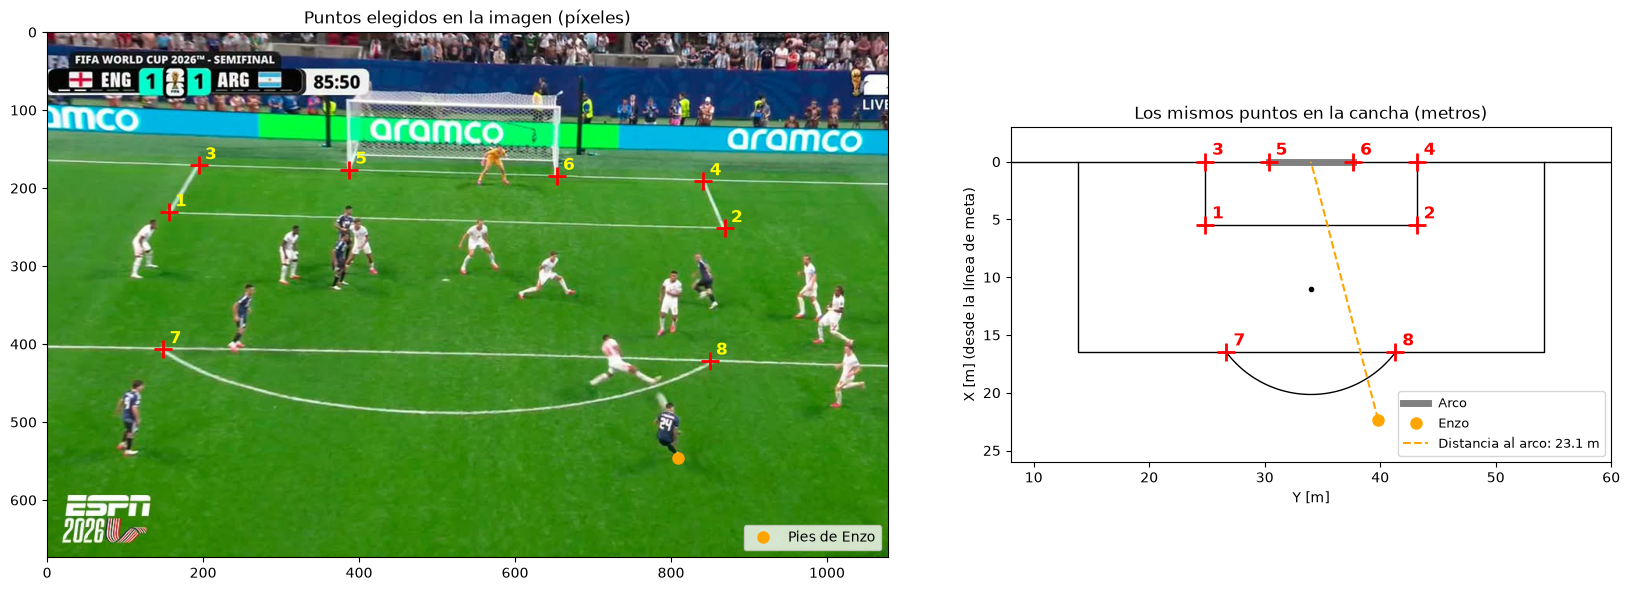

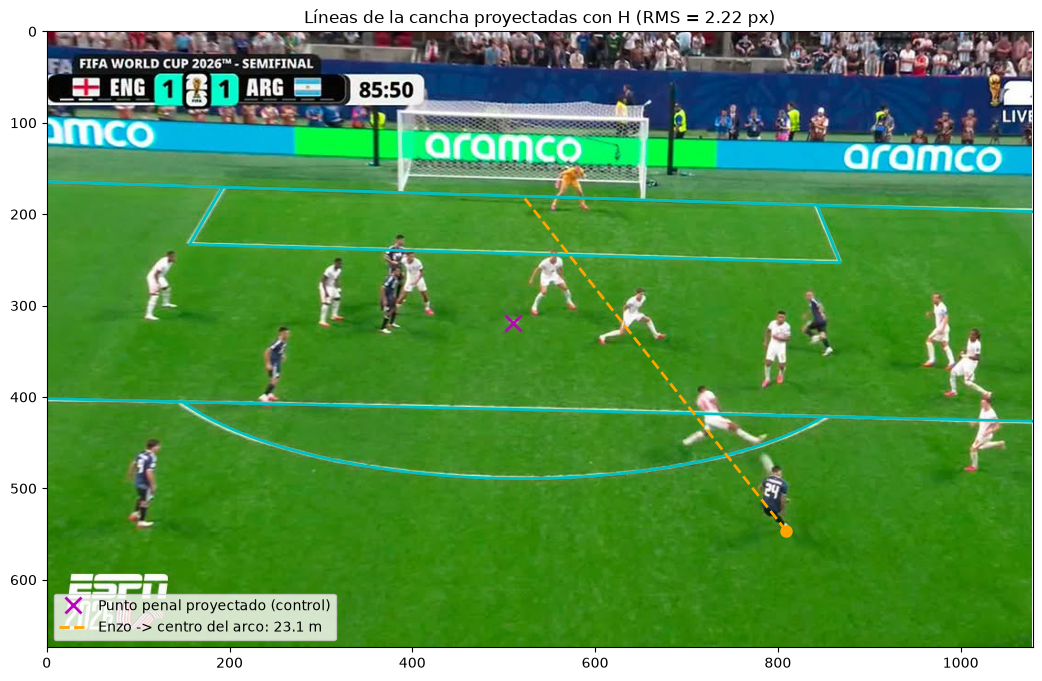

In [3]:
# Ejercicio 4 a) Homografía de la cancha y distancia de Enzo al arco
# ============================================================
 
img = cv2.imread('futbol/test-gol-enzo.png')
img_rgb = img[:, :, ::-1] 

# Puntos de referencia en la imagen (u, v), leídos del gráfico anterior
imgPts = np.array([
    [155.9, 231.1], # Area chica: esquina frontal izq
    [868.8, 251.5], # Area chica: esquina frontal der
    [194.4, 171.0], # Area chica con línea de meta (izq)
    [841.6, 191.4], # Area chica con línea de meta (der)
    [387.1, 176.7], # Base del palo izquierdo
    [653.5, 184.6], # Base del palo derecho
    [149.1, 406.8], # Medialuna corta la línea del área grande (izq)
    [849.6, 421.5], # Medialuna corta la línea del área grande (der)
], dtype=np.float32)

# Los mismos puntos en coordenadas de la cancha (X, Y) en metros,
# con el origen en la esquina del arco y X medido desde la línea de meta.
objPts = np.array([
    [ 5.5, 24.84],  # 1. Área chica: esquina frontal izq
    [ 5.5, 43.16],  # 2. Área chica: esquina frontal der
    [ 0.0, 24.84],  # 3. Área chica con línea de meta (izq)
    [ 0.0, 43.16],  # 4. Área chica con línea de meta (der)
    [ 0.0, 30.34],  # 5. Base del palo izquierdo
    [ 0.0, 37.66],  # 6. Base del palo derecho
    [16.5, 26.69],  # 7. Medialuna con línea del área grande (izq)
    [16.5, 41.31],  # 8. Medialuna con línea del área grande (der)
], dtype=np.float32)

# ------------------------------------------------------------
# Homografía cancha -> imagen
# ------------------------------------------------------------
# DLT con normalización de Hartley: estimarH arma Q con obtenerQ2d y toma
# el autovector de menor autovalor de Q^T Q.
H = estimarH(imgPts, objPts)
 
# ------------------------------------------------------------
# Verificación: error de reproyección
# ------------------------------------------------------------
# Proyectamos los puntos de la cancha con H y medimos la distancia, en
# píxeles, a donde los marcamos en la foto.
P_cancha = np.vstack([objPts.T, np.ones(objPts.shape[0])])     # (3, 8)
proy = multiplicacionMatricial(H, P_cancha)
u_proy = proy[0] / proy[2]
v_proy = proy[1] / proy[2]
 
errores = np.sqrt((u_proy - imgPts[:, 0])**2 + (v_proy - imgPts[:, 1])**2)
rms = np.sqrt(np.mean(errores**2))
 
# ------------------------------------------------------------
# Posición de Enzo y distancia al arco
# ------------------------------------------------------------
u_enzo = 808.8      # píxel (u, v) de los pies de Enzo
v_enzo = 546.2
 
# Llevamos el píxel a la cancha con H^-1 y dividimos por la tercera componente
pt_real = prodMatV(inversa(H), np.array([u_enzo, v_enzo, 1]))
xReal = pt_real[0] / pt_real[2]
yReal = pt_real[1] / pt_real[2]
 
# Distancia al centro del arco, (X, Y) = (0, 34)
dist_arco = np.sqrt(xReal**2 + (yReal - 34)**2)
# A modo de comparación: distancia perpendicular a la línea de meta (X = 0)
dist_linea_meta = abs(xReal)
 
print(f"Pies de Enzo en la cancha (X, Y): ({xReal:.2f}, {yReal:.2f}) m")
print(f"Distancia al arco (centro):        {dist_arco:.2f} m")
print(f"Distancia a la línea de meta:      {dist_linea_meta:.2f} m")
 
# ------------------------------------------------------------
# Líneas de la cancha en metros (para el esquema y para validar H)
# ------------------------------------------------------------
angulo = np.arccos(5.5 / 9.15)                 # la medialuna es la parte con X >= 16,5
theta = np.linspace(-angulo, angulo, 100)
medialuna = np.column_stack([11 + 9.15 * np.cos(theta), 34 + 9.15 * np.sin(theta)])
 
lineas_cancha = [
    np.array([[0, 0], [0, 68]]),                                       # línea de meta
    np.array([[0, 13.84], [16.5, 13.84], [16.5, 54.16], [0, 54.16]]),  # área grande
    np.array([[0, 24.84], [5.5, 24.84], [5.5, 43.16], [0, 43.16]]),    # área chica
    medialuna,
]
 
# ------------------------------------------------------------
# Figura 1: puntos elegidos en la imagen y en la cancha
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.6, 1]})
 
ax1.imshow(img_rgb)
for i in range(imgPts.shape[0]):
    ax1.plot(imgPts[i, 0], imgPts[i, 1], 'r+', markersize=13, markeredgewidth=2)
    ax1.text(imgPts[i, 0] + 8, imgPts[i, 1] - 8, str(i + 1), color='yellow',
             fontsize=12, fontweight='bold')
ax1.plot(u_enzo, v_enzo, 'o', color='orange', markersize=8, label='Pies de Enzo')
ax1.set_title('Puntos elegidos en la imagen (píxeles)')
ax1.legend(loc='lower right')
 
# Esquema de la cancha: Y en horizontal y X en vertical, con el arco arriba como en la foto
for linea in lineas_cancha:
    ax2.plot(linea[:, 1], linea[:, 0], 'k-', linewidth=1)
ax2.plot([30.34, 37.66], [0, 0], color='gray', linewidth=5, label='Arco')
ax2.plot(34, 11, 'k.', markersize=6)                                   # punto penal
for i in range(objPts.shape[0]):
    ax2.plot(objPts[i, 1], objPts[i, 0], 'r+', markersize=13, markeredgewidth=2)
    ax2.text(objPts[i, 1] + 0.6, objPts[i, 0] - 0.6, str(i + 1), color='red',
             fontsize=12, fontweight='bold')
ax2.plot(yReal, xReal, 'o', color='orange', markersize=8, label='Enzo')
ax2.plot([yReal, 34], [xReal, 0], '--', color='orange',
         label=f'Distancia al arco: {dist_arco:.1f} m')
ax2.set_xlim(8, 60)
ax2.set_ylim(26, -3)
ax2.set_aspect('equal')
ax2.set_xlabel('Y [m]')
ax2.set_ylabel('X [m] (desde la línea de meta)')
ax2.set_title('Los mismos puntos en la cancha (metros)')
ax2.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()
 
# ------------------------------------------------------------
# Figura 2: validación de H, líneas de la cancha proyectadas sobre la foto
# ------------------------------------------------------------
# Si H es correcta, las líneas proyectadas caen sobre las pintadas.
plt.figure(figsize=(13, 8))
plt.imshow(img_rgb)
 
for linea in lineas_cancha:
    P = np.vstack([linea.T, np.ones(linea.shape[0])])
    q = multiplicacionMatricial(H, P)
    plt.plot(q[0] / q[2], q[1] / q[2], 'c-', linewidth=2)
 
# Punto penal: no se usó para estimar H, sirve de control
q_penal = prodMatV(H, np.array([11, 34, 1]))
plt.plot(q_penal[0] / q_penal[2], q_penal[1] / q_penal[2], 'mx', markersize=12,
         markeredgewidth=2, label='Punto penal proyectado (control)')
 
# Segmento de Enzo al centro del arco
q_arco = prodMatV(H, np.array([0, 34, 1]))
plt.plot([u_enzo, q_arco[0] / q_arco[2]], [v_enzo, q_arco[1] / q_arco[2]], '--',
         color='orange', linewidth=2, label=f'Enzo -> centro del arco: {dist_arco:.1f} m')
plt.plot(u_enzo, v_enzo, 'o', color='orange', markersize=8)
 
plt.xlim(0, img_rgb.shape[1])
plt.ylim(img_rgb.shape[0], 0)
plt.title(f'Líneas de la cancha proyectadas con H (RMS = {rms:.2f} px)')
plt.legend(loc='lower left')
plt.show()

El campo de juego es un plano, así que la relación entre sus puntos
$(X, Y, 1)^T$ y los píxeles $(u, v, 1)^T$ de la foto es una homografía $H$:

$$\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = H \begin{bmatrix} X \\ Y \\ 1 \end{bmatrix}$$

Para este ejercicio no necesitamos $K$ ni descomponer $H$ en $R$ y $t$: alcanza con $H$ y su inversa.

**Sistema de coordenadas de la cancha.** $X$ se mide desde la línea de meta hacia el campo
e $Y$ a lo ancho de la cancha (68 m), de modo que el centro del arco es $(X, Y) = (0, 34)$.

**Elección de los puntos.** La homografía solo relaciona puntos **del plano de la cancha**,
así que usamos únicamente marcas que se ven en la foto y que están sobre el piso. Las
esquinas del área grande quedan fuera de la imagen, y el travesaño y los carteles no están
en el plano del piso, por lo que no sirven. Elegimos 8 puntos cuyas coordenadas salen de
las medidas reglamentarias:

- Las 4 esquinas del área chica (18,32 m × 5,5 m): $Y = 34 \pm 9{,}16$, $X = 0$ y $X = 5{,}5$.
- La base de los dos palos (arco de 7,32 m): $Y = 34 \pm 3{,}66$, $X = 0$.
- Los cortes de la medialuna (radio 9,15 m desde el penal, en $(11, 34)$) con la línea
  del área grande ($X = 16{,}5$): $(16{,}5 - 11)^2 + (Y - 34)^2 = 9{,}15^2$, de donde $Y = 34 \pm 7{,}31$.

Los píxeles se marcaron con zoom sobre el cruce de las líneas. La primera figura muestra
cada punto numerado en la foto y en el esquema de la cancha.

**Procedimiento.**
1. Estimamos $H$ con DLT (sistema $Qh = 0$) y normalización de Hartley. La solución es el
   autovector de $Q^TQ$ de menor autovalor, que minimiza $\|Qh\|$ con $\|h\| = 1$.
2. Verificamos $H$ de dos formas:
   - **Error de reproyección:** proyectamos los 8 puntos de la cancha con $H$. El RMS es
     de 2,2 px y ningún punto supera los 4 px.
   - **Líneas de la cancha:** proyectamos con $H$ el área chica, la línea de meta, la línea
     del área grande y la medialuna. Las líneas proyectadas coinciden con las pintadas
     (segunda figura). Además, el punto penal, que no se usó para estimar $H$, cae en una
     posición coherente.
3. Llevamos los pies de Enzo, $(u, v) = (808{,}8;\ 546{,}2)$, a la cancha con $H^{-1}$ y
   dividimos por la tercera componente: $(X, Y) = (x'/z',\ y'/z')$.
4. Calculamos la distancia al centro del arco: $d = \sqrt{X^2 + (Y - 34)^2}$.

**Resultado.** Los pies de Enzo se ubican en $(X, Y) \approx (22{,}32;\ 39{,}81)$ m, por lo
que patea a aproximadamente **23,1 m del arco** (medido al centro del arco). La distancia
perpendicular a la línea de meta sería de 22,3 m: es menor porque Enzo está corrido unos
5,8 m hacia un costado del arco.

**Observación.** Los pies de Enzo están más cerca de la cámara que todos los puntos de
referencia, así que su posición se obtiene extrapolando $H$ fuera de la zona que cubren
esos puntos. Esto puede agregar algo de error, aunque la buena coincidencia de las líneas
proyectadas indica que $H$ es confiable.

Posición de los jugadores argentinos en la cancha:
  Jugador 1: (X, Y) = (22.44, 26.90) m
  Jugador 2: (X, Y) = (16.22, 28.63) m
  Jugador 3: (X, Y) = (11.52, 30.90) m
  Jugador 4: (X, Y) = ( 9.71, 31.01) m
  Jugador 5: (X, Y) = (22.32, 39.81) m
  Jugador 6: (X, Y) = (12.69, 41.72) m


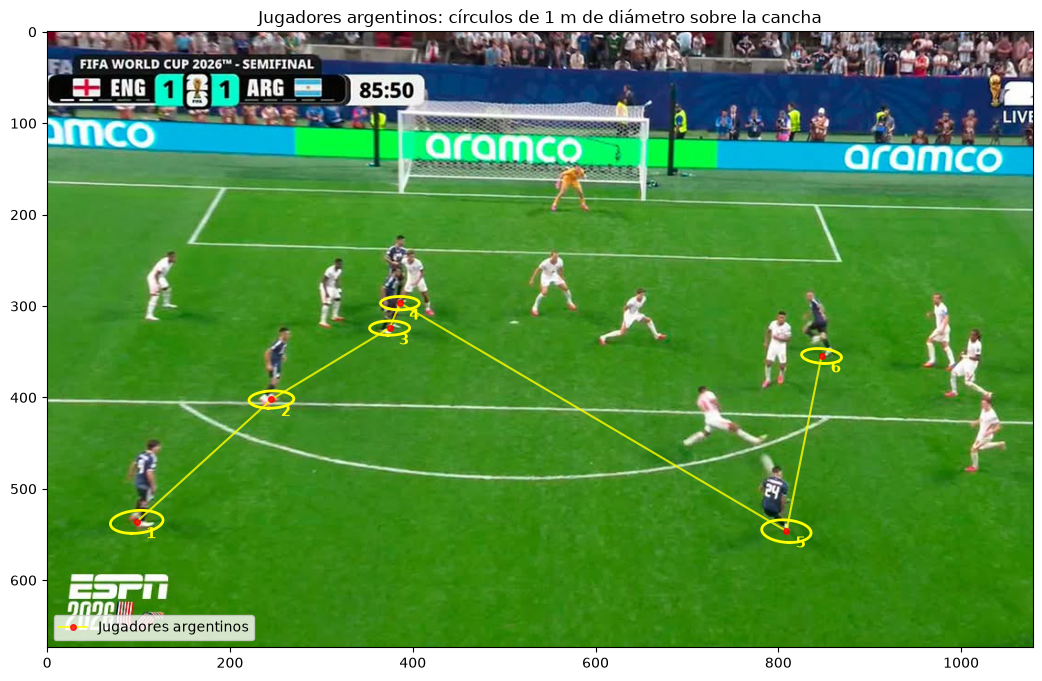

In [4]:
# Ejercicio 4 b)
# ============================================================
# Usamos la H estimada en la celda anterior (cancha -> imagen).
 
# ------------------------------------------------------------
# Píxeles (u, v, 1) de los pies de los jugadores argentinos
# ------------------------------------------------------------
# Cada columna es un jugador. Marcamos con zoom el punto medio entre sus pies,
# porque la homografía solo vale para puntos sobre el piso.
# La 5ta columna son los pies de Enzo, el mismo píxel de la celda anterior.
# El 4to jugador está detrás de un compañero: sus pies se estiman parcialmente tapados.
Pimg = np.array([[ 98.1, 245.4, 374.7, 386.0, 808.8, 847.3],   # u
                 [536.0, 402.2, 324.0, 296.8, 546.2, 354.6],   # v
                 [  1.0,   1.0,   1.0,   1.0,   1.0,   1.0]])
n_jugadores = Pimg.shape[1]
 
# ------------------------------------------------------------
# Llevamos los jugadores de la imagen a la cancha: (X, Y, 1) ~ H^-1 (u, v, 1)
# ------------------------------------------------------------
PtsReales = multiplicacionMatricial(inversa(H), Pimg)
PtsReales = PtsReales / PtsReales[2, :]        # dividimos por la tercera fila
 
X_reales = PtsReales[0, :]
Y_reales = PtsReales[1, :]
 
print("Posición de los jugadores argentinos en la cancha:")
for i in range(n_jugadores):
    print(f"  Jugador {i + 1}: (X, Y) = ({X_reales[i]:5.2f}, {Y_reales[i]:5.2f}) m")
 
# ------------------------------------------------------------
# Círculo de 1 m de diámetro, definido en la cancha (en metros)
# ------------------------------------------------------------
radio = 0.5                                     # 1 m de diámetro
theta = np.linspace(0, 2 * np.pi, 100)
X_circ = radio * np.cos(theta)
Y_circ = radio * np.sin(theta)
 
# ------------------------------------------------------------
# Proyectamos cada círculo a la imagen con H
# ------------------------------------------------------------
plt.figure(figsize=(13, 8))
plt.imshow(img_rgb)
 
for i in range(n_jugadores):
    # Círculo centrado en la posición del jugador i, en homogéneas (X, Y, 1)
    CirculoReal = np.vstack([X_reales[i] + X_circ,
                             Y_reales[i] + Y_circ,
                             np.ones(theta.shape[0])])
 
    # (u, v, 1) ~ H (X, Y, 1), y dividimos por la tercera fila
    CirculoImg = multiplicacionMatricial(H, CirculoReal)
    CirculoImg = CirculoImg / CirculoImg[2, :]
 
    plt.plot(CirculoImg[0, :], CirculoImg[1, :], color='yellow', linewidth=2)
    plt.text(Pimg[0, i] + 10, Pimg[1, i] + 18, str(i + 1), color='yellow',
             fontsize=11, fontweight='bold')
 
# Unimos a los jugadores con una línea que pasa por el centro de cada círculo.
# Un segmento recto en la cancha sigue siendo recto en la imagen (H conserva
# las rectas), así que alcanza con unir los píxeles de los pies.
plt.plot(Pimg[0, :], Pimg[1, :], color='yellow', linestyle='-', linewidth=1.5,
         alpha=0.8, marker='.', markersize=8, markerfacecolor='red',
         markeredgecolor='red', label='Jugadores argentinos')
 
plt.title("Jugadores argentinos: círculos de 1 m de diámetro sobre la cancha")
plt.legend(loc='lower left')
plt.show()

**Idea.** Ubicamos a cada jugador argentino en la cancha y dibujamos, sobre el piso, un
círculo de 1 m de diámetro centrado en sus pies. Como todo ocurre sobre el plano de la
cancha, usamos la misma homografía $H$ estimada antes.

**Procedimiento.**
1. Marcamos en la imagen, con zoom, el punto medio entre los pies de los 6 jugadores
   argentinos. Usamos los pies porque $H$ solo vale para puntos sobre el piso. El jugador 4
   está parcialmente tapado por un compañero, así que la posición de sus pies es aproximada.
2. Los llevamos a la cancha con $H^{-1}$ y normalizamos por la tercera componente,
   obteniendo $(X_i, Y_i)$ en metros.
3. Definimos en la cancha un círculo de radio $r = 0{,}5$ m centrado en cada jugador:
   $(X_i + r\cos\theta,\ Y_i + r\sin\theta)$, con $\theta \in [0, 2\pi]$.
4. Proyectamos esos puntos a la imagen con $H$ y los dibujamos.

**Resultado.** En la imagen los círculos se ven como **elipses**: la perspectiva no
conserva las circunferencias. Las elipses son más chicas y más achatadas cuanto más lejos
de la cámara está el jugador, porque un mismo metro ocupa menos píxeles a mayor distancia.
Que todas tengan una forma coherente con la perspectiva confirma que $H$ está bien estimada.

Error de reproyección por punto:
  Punto 1: 0.61 px
  Punto 2: 1.11 px
  Punto 3: 0.50 px
  Punto 4: 0.80 px
  Punto 5: 0.60 px
  Punto 6: 0.43 px
  Punto 7: 0.58 px
  Punto 8: 1.64 px
RMS: 0.87 px

Defensores (X en metros, mayor = más cerca del arco):
  píxel (1435, 465): X = 102.49
  píxel (812, 328): X = 90.37  <- último defensor (penúltimo contando al arquero)
  píxel (795, 563): X = 89.56
  píxel (770, 367): X = 89.28
  píxel (745, 538): X = 88.67

Línea de offside: X = 90.37 m (14.63 m de la línea de meta)

Atacantes:
  píxel (870, 590): X = 90.82 -> +0.45 m respecto de la línea: ADELANTADO (offside)
  píxel (848, 517): X = 90.62 -> +0.24 m respecto de la línea: ADELANTADO (offside)
  píxel (792, 467): X = 89.63 -> -0.75 m respecto de la línea: habilitado
  píxel (795, 347): X = 89.91 -> -0.47 m respecto de la línea: habilitado


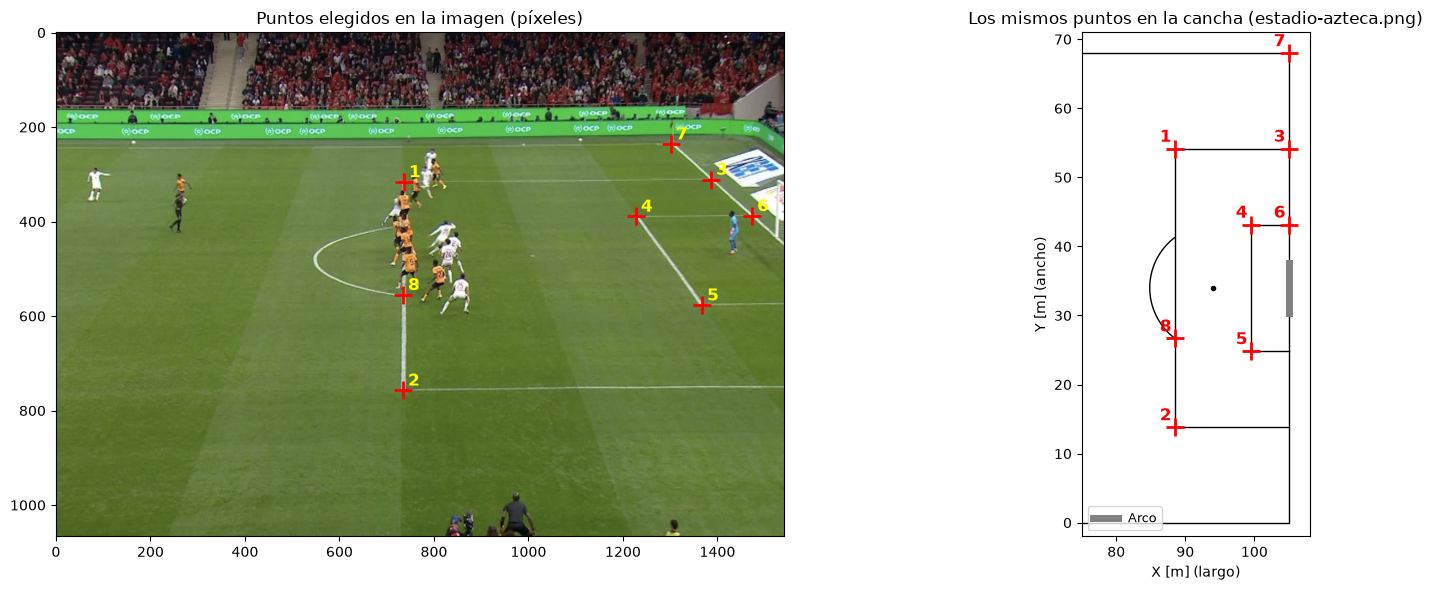

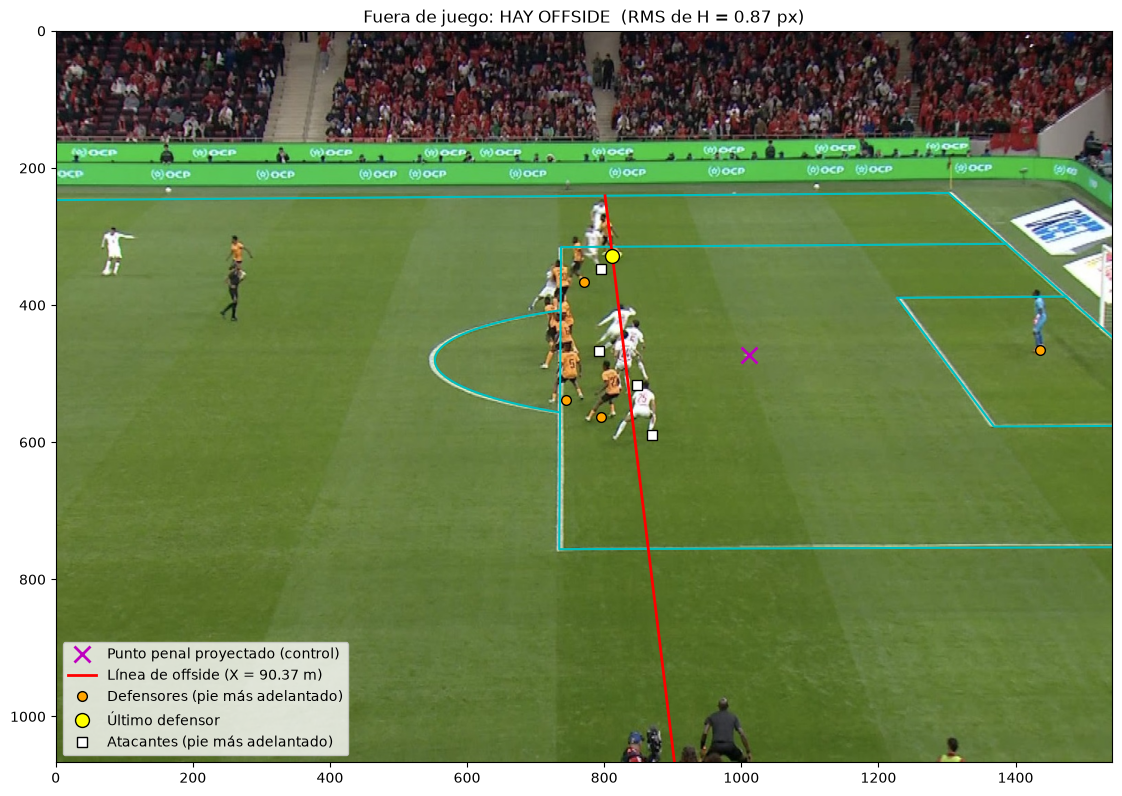

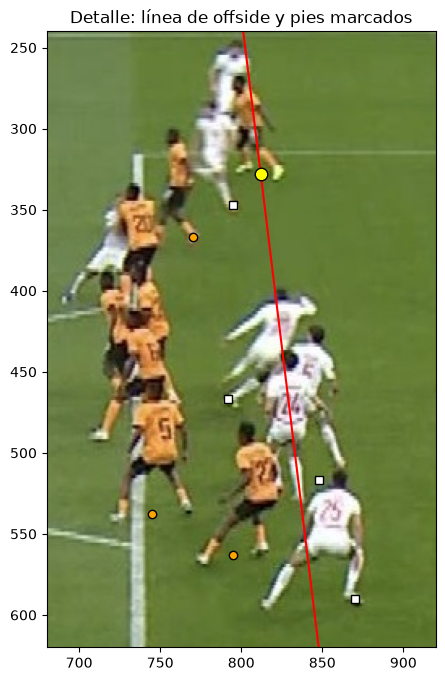

In [7]:
# Ejercicio 4 c) Fuera de juego: recta paralela a la línea de fondo
# ============================================================

img2 = cv2.imread('futbol/test-fuera-de-juego.png')
img2_rgb = img2[:, :, ::-1]                    # BGR (OpenCV) -> RGB (matplotlib)

# ------------------------------------------------------------
# Correspondencias imagen <-> cancha
# ------------------------------------------------------------
# Sistema de estadio-azteca.png: origen en la esquina inferior izquierda,
# X a lo largo (0 a 105 m) e Y a lo ancho (0 a 68 m). El arco de esta foto
# está sobre la línea de meta X = 105, y la línea de fondo lejana de la foto
# es la banda Y = 68.
# Solo usamos marcas visibles y sobre el piso, marcadas con zoom en el cruce
# de las líneas:
#   Área grande: X = 105 - 16,5 = 88,5;  Y = 34 +- 20,16
#   Área chica:  X = 105 - 5,5  = 99,5;  Y = 34 +- 9,16
#   Medialuna: radio 9,15 m desde el penal (94, 34). Corta X = 88,5 en
#   (94 - 88,5)^2 + (Y - 34)^2 = 9,15^2   ->   Y = 34 +- 7,31
imgPts2 = np.array([
    [ 737.0, 316.0],  # 1. Área grande: esquina frontal lejana
    [ 735.0, 757.0],  # 2. Área grande: esquina frontal cercana
    [1387.0, 311.0],  # 3. Área grande (lateral lejano) con línea de meta
    [1228.0, 389.0],  # 4. Área chica: esquina frontal lejana
    [1368.0, 577.0],  # 5. Área chica: esquina frontal cercana
    [1474.0, 388.0],  # 6. Área chica (lateral lejano) con línea de meta
    [1302.0, 236.0],  # 7. Esquina de la cancha (banda lejana con línea de meta)
    [ 735.0, 555.0],  # 8. Medialuna corta la línea del área grande (lado cercano)
])

objPts2 = np.array([
    [ 88.5, 54.16],  # 1
    [ 88.5, 13.84],  # 2
    [105.0, 54.16],  # 3
    [ 99.5, 43.16],  # 4
    [ 99.5, 24.84],  # 5
    [105.0, 43.16],  # 6
    [105.0, 68.00],  # 7
    [ 88.5, 26.69],  # 8
])

# ------------------------------------------------------------
# Homografía de esta foto (cancha -> imagen)
# ------------------------------------------------------------
# DLT con normalización de Hartley. La llamamos H_fuera para no pisar la H del inciso a).
H_fuera = estimarH(imgPts2, objPts2)
H_fuera_inv = inversa(H_fuera)

# Error de reproyección
P_cancha = np.vstack([objPts2.T, np.ones(objPts2.shape[0])])
proy = multiplicacionMatricial(H_fuera, P_cancha)
u_proy = proy[0] / proy[2]
v_proy = proy[1] / proy[2]
errores = np.sqrt((u_proy - imgPts2[:, 0])**2 + (v_proy - imgPts2[:, 1])**2)
rms = np.sqrt(np.mean(errores**2))

print("Error de reproyección por punto:")
for i in range(errores.shape[0]):
    print(f"  Punto {i + 1}: {errores[i]:.2f} px")
print(f"RMS: {rms:.2f} px\n")

# ------------------------------------------------------------
# Jugadores: píxel del pie más adelantado (el más cercano al arco)
# ------------------------------------------------------------
# Defensores (naranja), incluido el arquero.
defensores_img = np.array([
    [ 812.0, 328.0],   # naranja arriba a la derecha
    [ 795.0, 563.0],   # naranja 27
    [ 745.0, 538.0],   # naranja 5
    [ 770.0, 367.0],   # naranja junto a la línea del área
    [1435.0, 465.0],   # arquero
])
# Atacantes (blanco) cerca de la línea.
atacantes_img = np.array([
    [ 870.0, 590.0],   # blanco 25
    [ 848.0, 517.0],   # blanco 24
    [ 792.0, 467.0],   # blanco 22
    [ 795.0, 347.0],   # blanco de arriba
])

# Pasamos todos los pies a la cancha con H^-1
D = multiplicacionMatricial(H_fuera_inv, np.vstack([defensores_img.T, np.ones(defensores_img.shape[0])]))
X_def_todos = D[0] / D[2]
Y_def_todos = D[1] / D[2]
A = multiplicacionMatricial(H_fuera_inv, np.vstack([atacantes_img.T, np.ones(atacantes_img.shape[0])]))
X_atac = A[0] / A[2]
Y_atac = A[1] / A[2]

# El arco está en X = 105: cuanto mayor es X, más cerca del arco.
# Último defensor = penúltimo rival contando al arquero = el segundo X más grande.
orden = np.argsort(X_def_todos)[::-1]
i_def = orden[1]
X_def = X_def_todos[i_def]

print("Defensores (X en metros, mayor = más cerca del arco):")
for i in orden:
    marca = "  <- último defensor (penúltimo contando al arquero)" if i == i_def else ""
    print(f"  píxel ({defensores_img[i, 0]:.0f}, {defensores_img[i, 1]:.0f}): X = {X_def_todos[i]:.2f}{marca}")

print(f"\nLínea de offside: X = {X_def:.2f} m ({105 - X_def:.2f} m de la línea de meta)\n")

print("Atacantes:")
for i in range(atacantes_img.shape[0]):
    dif = X_atac[i] - X_def
    estado = "ADELANTADO (offside)" if dif > 0 else "habilitado"
    print(f"  píxel ({atacantes_img[i, 0]:.0f}, {atacantes_img[i, 1]:.0f}): X = {X_atac[i]:.2f} "
          f"-> {dif:+.2f} m respecto de la línea: {estado}")

hay_offside = np.max(X_atac) > X_def

# ------------------------------------------------------------
# Líneas de la cancha en metros (esquema y validación de H)
# ------------------------------------------------------------
angulo = np.arccos(5.5 / 9.15)                 # parte de la medialuna con X <= 88,5
theta = np.linspace(np.pi - angulo, np.pi + angulo, 100)
medialuna = np.column_stack([94 + 9.15 * np.cos(theta), 34 + 9.15 * np.sin(theta)])

lineas_cancha = [
    np.array([[52.5, 68], [105, 68], [105, 0], [52.5, 0]]),             # bandas y línea de meta
    np.array([[105, 13.84], [88.5, 13.84], [88.5, 54.16], [105, 54.16]]),  # área grande
    np.array([[105, 24.84], [99.5, 24.84], [99.5, 43.16], [105, 43.16]]),  # área chica
    medialuna,
]

# ------------------------------------------------------------
# Figura 1: puntos elegidos en la imagen y en el plano de la cancha
# ------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.5, 1]})

ax1.imshow(img2_rgb)
for i in range(imgPts2.shape[0]):
    ax1.plot(imgPts2[i, 0], imgPts2[i, 1], 'r+', markersize=13, markeredgewidth=2)
    ax1.text(imgPts2[i, 0] + 10, imgPts2[i, 1] - 10, str(i + 1), color='yellow',
             fontsize=12, fontweight='bold')
ax1.set_title('Puntos elegidos en la imagen (píxeles)')

for linea in lineas_cancha:
    ax2.plot(linea[:, 0], linea[:, 1], 'k-', linewidth=1)
ax2.plot([105, 105], [30.34, 37.66], color='gray', linewidth=5, label='Arco')
ax2.plot(94, 34, 'k.', markersize=6)
for i in range(objPts2.shape[0]):
    ax2.plot(objPts2[i, 0], objPts2[i, 1], 'r+', markersize=13, markeredgewidth=2)
    ax2.text(objPts2[i, 0] - 2.2, objPts2[i, 1] + 1, str(i + 1), color='red',
             fontsize=12, fontweight='bold')
ax2.set_xlim(75, 108)
ax2.set_ylim(-2, 71)
ax2.set_aspect('equal')
ax2.set_xlabel('X [m] (largo)')
ax2.set_ylabel('Y [m] (ancho)')
ax2.set_title('Los mismos puntos en la cancha (estadio-azteca.png)')
ax2.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figura 2: validación de H y línea de offside
# ------------------------------------------------------------
plt.figure(figsize=(14, 9.5))
plt.imshow(img2_rgb)

# Líneas de la cancha proyectadas: si H es correcta, caen sobre las pintadas
for linea in lineas_cancha:
    q = multiplicacionMatricial(H_fuera, np.vstack([linea.T, np.ones(linea.shape[0])]))
    plt.plot(q[0] / q[2], q[1] / q[2], 'c-', linewidth=1.5)

# Punto penal: no se usó para estimar H, sirve de control
q_penal = prodMatV(H_fuera, np.array([94, 34, 1]))
plt.plot(q_penal[0] / q_penal[2], q_penal[1] / q_penal[2], 'mx', markersize=12,
         markeredgewidth=2, label='Punto penal proyectado (control)')

# Línea de offside: X = X_def en toda la cancha (Y de 0 a 68), proyectada con H
Y_recta = np.linspace(0, 68, 100)
RectaReal = np.vstack([X_def * np.ones(100), Y_recta, np.ones(100)])
RectaImg = multiplicacionMatricial(H_fuera, RectaReal)
plt.plot(RectaImg[0] / RectaImg[2], RectaImg[1] / RectaImg[2], 'r-', linewidth=2,
         label=f'Línea de offside (X = {X_def:.2f} m)')

plt.plot(defensores_img[:, 0], defensores_img[:, 1], 'o', color='orange',
         markeredgecolor='black', markersize=7, label='Defensores (pie más adelantado)')
plt.plot(defensores_img[i_def, 0], defensores_img[i_def, 1], 'o', color='yellow',
         markeredgecolor='black', markersize=10, label='Último defensor')
plt.plot(atacantes_img[:, 0], atacantes_img[:, 1], 's', color='white',
         markeredgecolor='black', markersize=7, label='Atacantes (pie más adelantado)')

plt.xlim(0, img2_rgb.shape[1])
plt.ylim(img2_rgb.shape[0], 0)
conclusion = "HAY OFFSIDE" if hay_offside else "NO hay offside"
plt.title(f'Fuera de juego: {conclusion}  (RMS de H = {rms:.2f} px)')
plt.legend(loc='lower left')
plt.show()

# Detalle de la jugada, ampliado
plt.figure(figsize=(8, 8))
plt.imshow(img2_rgb)
plt.plot(RectaImg[0] / RectaImg[2], RectaImg[1] / RectaImg[2], 'r-', linewidth=1.5)
plt.plot(defensores_img[:, 0], defensores_img[:, 1], 'o', color='orange', markeredgecolor='black')
plt.plot(defensores_img[i_def, 0], defensores_img[i_def, 1], 'o', color='yellow',
         markeredgecolor='black', markersize=9)
plt.plot(atacantes_img[:, 0], atacantes_img[:, 1], 's', color='white', markeredgecolor='black')
plt.xlim(680, 920)
plt.ylim(620, 240)
plt.title('Detalle: línea de offside y pies marcados')
plt.show()

**Idea.** La línea de fuera de juego es paralela a la línea de meta y pasa por el pie más
adelantado del último defensor (el penúltimo jugador rival, contando al arquero). En
coordenadas de la cancha es la recta $X = X_{def}$; la proyectamos a la imagen con la
homografía de esta foto.

**Elección de los puntos.** Usamos el sistema de `estadio-azteca.png` (origen en la esquina
inferior izquierda, arco en $X = 105$). Elegimos 8 marcas visibles y sobre el piso: esquinas
del área grande y del área chica, sus cortes con la línea de meta, la esquina de la cancha
y el corte de la medialuna con la línea del área. En la primera figura se ven numeradas
en la foto y en el plano.

**Procedimiento.**
1. Estimamos $H$ con DLT y normalización de Hartley. El RMS de reproyección es de 0,87 px,
   y las líneas de la cancha proyectadas coinciden con las pintadas. El punto penal, que no
   se usó para estimar $H$, cae en su lugar.
2. Llevamos a la cancha, con $H^{-1}$, el pie más adelantado de cada defensor y de cada
   atacante cercano a la línea.
3. Ordenamos a los defensores por $X$ (mayor $X$ = más cerca del arco) y tomamos el segundo,
   ya que el primero es el arquero: $X_{def} \approx 90{,}37$ m.
4. Proyectamos la recta $\{(X_{def}, Y) : Y \in [0, 68]\}$ con $H$. En la imagen no se ve
   paralela a la línea del área, sino que converge con ella hacia el mismo punto de fuga,
   como corresponde a dos rectas paralelas vistas en perspectiva.
5. Un atacante está adelantado si su $X$ supera a $X_{def}$.

**Conclusión.** Los atacantes 24 y 25 están adelantados respecto de la línea
(+0,24 m y +0,45 m), así que **hay fuera de juego**. La diferencia es de pocos
centímetros, del orden de 10 a 20 píxeles en la imagen, por lo que el resultado es sensible
a la precisión con que se marcan los pies. Además, usamos el pie como aproximación: el
reglamento considera cualquier parte del cuerpo con la que se pueda jugar la pelota,
excepto brazos y manos.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [ ]:
A = alc.parametrosIntrinsecosEj5a()
print(A)

Para calcular los parámetros intrínsecos de una cámara (matriz K) mediante calibración coplanar (método de Zhang), es suficiente con tomar al menos 3 fotografías desde distintas perspectivas de un plano con puntos de control de geometría conocida.

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [ ]:
K = alc.parametrosIntrinsecosEj5a()

datos = np.loadtxt("salguero/gs_10_09_point_correspondences_v5.txt")

objPts_b = datos[1:3, :].T  # Extraemos ejes X,Y de la foto 2d. Matriz de (51x2)
imgPts_b = datos[4:6, :].T  # Extraemos u, v que son las coordenadas en píxeles (u la columna y v la fila de la foto). Matriz de (51x2)

#Homografía de la imagen inicial (ya calculada en a) y pose con la K de a)
H_b = estimarH(imgPts_b, objPts_b)
R_b, t_b = alc.obtenerPose2D(H_b, K)

#Como W = 0, la proyección es K * [r1 r2 t] * (X, Y, 1)
M_b = multiplicacionMatricial(K, np.hstack([R_b[:, :2], t_b.reshape(3, 1)]))
P = np.hstack([objPts_b, np.ones((objPts_b.shape[0], 1))])      # (X, Y, 1)
proj = (multiplicacionMatricial(M_b, P.T)).T

#Verificamos que todos los puntos quedan delante de la cámara (Z_c > 0)
print("Todos delante de la cámara:", np.all(proj[:, 2] > 0))

#Pasamos a píxeles dividiendo por la tercera componente
u_proj = proj[:, 0] / proj[:, 2]
v_proj = proj[:, 1] / proj[:, 2]

#Error de reproyección por punto y RMS, en píxeles
errores = np.sqrt((u_proj - imgPts_b[:, 0])**2 + (v_proj - imgPts_b[:, 1])**2)
rms_b = np.sqrt(np.mean(errores**2))

#Centro de la cámara en el sistema del mundo: C = -R^T t
C_b = -alc.calcularAx((R_b).T, t_b)

print("R_b:\n", np.round(R_b, 4))
print("t_b (m):", np.round(t_b, 4))
print("Centro de la cámara (m):", np.round(C_b, 2))
print(f"RMS de reproyección: {rms_b:.2f} px | error máximo: {np.max(errores):.1f} px")

#Reproyección sobre la imagen inicial
img = cv2.imread("salguero/img_10_18_47_351.jpg")
plt.figure(figsize=(12, 8))
plt.imshow(img[:, :, ::-1])
plt.scatter(imgPts_b[:, 0], imgPts_b[:, 1], color='lime', s=20, label='Puntos marcados')
plt.scatter(u_proj, v_proj, color='red', s=20, label='Reproyección con K, R, t')
plt.title("Reproyección de los 51 puntos")
plt.legend()
plt.show()

Se obtuvo la siguiente pose, que transforma coordenadas del mundo al sistema de la cámara:

$$
R_b =
\begin{pmatrix}
0.9610 & 0.2749 & 0.0307\
0.0491 & -0.0604 & -0.9970\
-0.2722 & 0.9596 & -0.0716
\end{pmatrix},
\qquad
t_b =
\begin{pmatrix}
-16.9438\
40.4260\
27.0261
\end{pmatrix}\text{ m}.
$$

El centro de la cámara, calculado mediante $C_b=-R_b^Tt_b$, es:

$$
C_b =
\begin{pmatrix}
21.65\
-18.83\
42.76
\end{pmatrix}\text{ m}.
$$

Todos los puntos evaluados presentan profundidad positiva. Sin embargo, el RMS de reproyección es de 191.08 píxeles, con un error máximo de 484.5 píxeles. Estos errores indican una discrepancia considerable entre las posiciones observadas y las proyectadas, por lo que la pose no puede considerarse validada.

La implementación utilizada descarta las coordenadas Z y supone que todos los puntos pertenecen al plano Z = 0. Esta hipótesis no respeta los datos del enunciado, que incluyen puntos del cordón a Z = 0.1 m. Es necesario conservar las coordenadas tridimensionales y revisar la calibración intrínseca y la estimación de pose antes de aceptar los resultados. La profundidad positiva es una condición necesaria, pero no garantiza una reproyección precisa.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

In [ ]:
datos = np.loadtxt("salguero/gs_10_09_point_correspondences_v5.txt")

objPts_b = datos[1:3, :].T  # Extraemos ejes X,Y de la foto 2d. Matriz de (51x2)
imgPts_b = datos[4:6, :].T  # Extraemos u, v que son las coordenadas en píxeles (u la columna y v la fila de la foto). Matriz de (51x2)

H_b = estimarH(imgPts_b, objPts_b)

datos_señora = np.loadtxt("salguero/coordenadas_senora.csv", delimiter=",", usecols=(1,2), skiprows= 1)
datos_auto = np.loadtxt("salguero/coordenadas_auto.csv", delimiter=",", usecols=(1,2), skiprows= 1)
datos_camion = np.loadtxt("salguero/coordenadas_camioneta.csv", delimiter=",", usecols=(1,2), skiprows= 1)


H_inv = alc.inversa(H_b)


#FUNCIONES AUXILIARES

def pixeles_a_metros(u, v, H_inv):
    """
    Recibe:
        u, v: coordenadas del punto en píxeles.
        H_inv: homografía inversa, de la imagen al plano de la calle.

    Devuelve:
        X_metros, Y_metros: coordenadas del punto en metros.

    Requiere que el punto esté sobre el plano de la homografía
    y que las coordenadas reales usadas para estimarla estén en metros.
    """
    # Representamos el píxel en coordenadas homogéneas.
    p_img = np.array([u, v, 1])

    # Aplicamos la homografía inversa.
    # El resultado tiene la forma [lambda*X, lambda*Y, lambda].
    p_w = alc.calcularAx(H_inv, p_img)

    # Eliminamos el factor de escala para recuperar las coordenadas reales.
    X_metros = p_w[0] / p_w[2]
    Y_metros = p_w[1] / p_w[2]

    return X_metros, Y_metros


def segundos_de_las_imagenes(nombre_del_archivo):
    """
    Recibe:
        nombre_del_archivo: nombre con formato img_HH_MM_SS_mmm.jpg.
        Por ejemplo: img_10_18_47_351.jpg.

    Devuelve:
        tiempo_en_segundos: instante de la captura expresado
        en segundos desde el inicio del día.
    """
    # Quitamos el prefijo y la extensión: queda "10_18_47_351".
    nombre_reducido = nombre_del_archivo.replace("img_", "").replace(".jpg", "")

    # Separamos las cuatro unidades de tiempo.
    unidades_de_tiempo = nombre_reducido.split("_")

    h = int(unidades_de_tiempo[0])
    m = int(unidades_de_tiempo[1])
    s = int(unidades_de_tiempo[2])
    ms = int(unidades_de_tiempo[3])

    # Convertimos horas, minutos y milisegundos a segundos.
    tiempo_en_segundos = h*3600 + m*60 + s + ms/1000

    return tiempo_en_segundos

#################################################################################

carpeta_imagenes = "salguero/Pruebas"

imagenes = [
    nombre
    for nombre in os.listdir(carpeta_imagenes)
    if nombre.startswith("img") and nombre.endswith(".jpg")
]

imagenes = sorted(imagenes, key=segundos_de_las_imagenes)

diferencias_tiempo = []

for i in range(len(imagenes) - 1):
    tiempo1 = segundos_de_las_imagenes(imagenes[i])
    tiempo2 = segundos_de_las_imagenes(imagenes[i + 1])

    dt = tiempo2 - tiempo1

    if dt <= 0:
        raise ValueError("Hay capturas con tiempos repetidos o incorrectos.")

    diferencias_tiempo.append(dt)


# En este punto, la lista "diferencias_tiempo" tiene como elementos la diferencia de tiempo entre imagen e imagen

# Primer elem de "diferencias_tiempo": dif de tiempo entre imagen 1 y 2.
# Segundo elem de "diferencias_tiempo": dif de tiempo entre imagen 2 y 3.
# etc.
  
diferencias_distancia_señora = []
diferencias_distancia_auto = []
diferencias_distancia_camion = []
    
for i in range(0, len(datos_señora)-1):
    u1, v1 = datos_señora[i][0], datos_señora[i][1]
    u2, v2 = datos_señora[i+1][0], datos_señora[i+1][1]
        
    X1, Y1 = pixeles_a_metros(u1, v1, H_inv)
    X2, Y2 = pixeles_a_metros(u2, v2, H_inv)
        
    distancia_señora = np.sqrt((X2-X1)**2 + (Y2-Y1)**2)
    diferencias_distancia_señora.append(distancia_señora)
        
    u3, v3 = datos_auto[i][0], datos_auto[i][1]
    u4, v4 = datos_auto[i+1][0], datos_auto[i+1][1]
        
    X3, Y3 = pixeles_a_metros(u3, v3, H_inv)
    X4, Y4 = pixeles_a_metros(u4, v4, H_inv)
        
    distancia_auto = np.sqrt((X4-X3)**2 + (Y4-Y3)**2)
    diferencias_distancia_auto.append(distancia_auto)
        
    u5, v5 = datos_camion[i][0], datos_camion[i][1]
    u6, v6 = datos_camion[i+1][0], datos_camion[i+1][1]
        
    X5, Y5 = pixeles_a_metros(u5, v5, H_inv)
    X6, Y6 = pixeles_a_metros(u6, v6, H_inv)
                
    distancia_camion = np.sqrt((X6-X5)**2 + (Y6-Y5)**2)
    diferencias_distancia_camion.append(distancia_camion)
        
# En este punto, se guardaron la diferencia de distancias (en metros) de la señora, el auto y el camion con respecto
# a cada imagen en sus respectivas listas

# Primer elemento: diferencia de distancia etnre imagen 1 y 2.
# Segundo elemento: diferencia de distancia etnre imagen 2 y 3.
# etc.

velocidad_señora = []
velocidad_auto = []
velocidad_camion = []

for i in range(0, len(diferencias_tiempo)):
    velocidad_s = diferencias_distancia_señora[i] / diferencias_tiempo[i]  # Velocidad de la señora entre cada imagen en m/s.
    velocidad_a = diferencias_distancia_auto[i] / diferencias_tiempo[i]    # Velocidad del auto entre cada imagen en m/s.
    velocidad_c = diferencias_distancia_camion[i] / diferencias_tiempo[i]  # Velocidad de la camioneta entre cada imagen en m/s.
    
    velocidad_señora.append(velocidad_s)
    velocidad_auto.append(velocidad_a)
    velocidad_camion.append(velocidad_c)

# En este punto, las velocidades de cada objeto entre imagen e imagen se guardaron en las listas correspondientes.

def mostrar_intervalos(nombre, imagenes, distancias, tiempos, velocidades):
    """
    Recibe:
        nombre: etiqueta del agente seguido.
        imagenes: nombres de las capturas en orden cronológico.
        distancias: distancias recorridas por intervalo, en metros.
        tiempos: duración de cada intervalo, en segundos.
        velocidades: rapidez por intervalo, en m/s.

    Imprime los datos de cada intervalo para revisar los resultados.
    No devuelve un resultado.
    """
    # Mostramos el nombre del agente.
    print("\n" + nombre)

    # Entre N imágenes hay N-1 intervalos.
    if len(distancias) != len(imagenes) - 1:
        raise ValueError(
            "La cantidad de posiciones no coincide con las imágenes."
        )

    # Mostramos las imágenes y las mediciones de cada intervalo.
    # round solo redondea la impresión; no modifica los datos guardados.
    for i in range(len(distancias)):
        print(
            imagenes[i], "->", imagenes[i + 1],
            "| distancia:", round(distancias[i], 3), "m",
            "| tiempo:", round(tiempos[i], 3), "s",
            "| rapidez:", round(velocidades[i], 3), "m/s"
        )

distancia_acumulada_señora = []
distancia_acumulada_auto = []
distancia_acumulada_camion = []

acum_s = 0
acum_a = 0
acum_c = 0

for i in range(0, len(diferencias_distancia_señora)):

    acum_s += diferencias_distancia_señora[i]
    acum_a += diferencias_distancia_auto[i]
    acum_c += diferencias_distancia_camion[i]

    distancia_acumulada_señora.append(acum_s)
    distancia_acumulada_auto.append(acum_a)
    distancia_acumulada_camion.append(acum_c)
    
# Con esto, calculo la distancia acumulada en cada intervalo, osea en cada imagen.
# Calculo la velocidad de cada uno 
vel_prom_señora = np.mean(velocidad_señora)
print("velocidad promedio señora")
print(vel_prom_señora)
vel_prom_auto = np.mean(velocidad_auto)
print("velocidad promedio auto")
print(vel_prom_auto)
vel_prom_camion = np.mean(velocidad_camion)
print("velocidad promedio camioneta")
print(vel_prom_camion)

plt.figure(figsize=(10,5))

plt.plot(distancia_acumulada_señora, velocidad_señora, label="Señora (de buzo rojo)", color="crimson", marker="o", linestyle="--")
plt.plot(distancia_acumulada_auto, velocidad_auto, label="Auto (taxi)", color="gold", marker="s", linestyle="-")
plt.plot(distancia_acumulada_camion, velocidad_camion, label="Camioneta", color="navy", marker="^", linestyle="-.")

plt.title("Velocidad en funcion de la distancia recorrida", fontsize=12)
plt.xlabel("Distancia recorrida (metros)", fontsize=10)
plt.ylabel("Velocidad (m/s)", fontsize=10) 
plt.legend()

plt.show()

Los promedios estimados entre capturas fueron 1.65 m/s para la señora, 1.97 m/s para el auto y 0.88 m/s para la camioneta.

Sin embargo, sospechamos que las estimaciones contienen errores porque presentan cambios bruscos entre capturas cercanas. En particular, la peatona alcanza aproximadamente 9.2 m/s, resultado incompatible con el movimiento de una persona caminando. El auto y la camioneta también presentan picos aislados que requieren revisión.

Las posibles causas incluyen imprecisiones al marcar las posiciones, cambios en el punto de referencia seguido y errores en la homografía utilizada para convertir píxeles a metros. En esta última se descartaron las coordenadas Z, tratando como coplanares puntos de la calle y del cordón que tienen distintas alturas. Además, los intervalos temporales pequeños amplifican el efecto de los errores de posición sobre la rapidez calculada.

Por estas razones, los resultados no permiten obtener conclusiones confiables sobre las velocidades reales. También queda pendiente representar las rapideces en función del tiempo, como solicita la consigna, ya que el gráfico obtenido utiliza la distancia acumulada.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

In [ ]:
np.set_printoptions(precision=8, suppress=True)

# Ajustar si el script se ejecuta desde otra carpeta.
carpeta = "heli"

K = np.loadtxt(
    os.path.join(carpeta, "K.csv"),
    delimiter=";"
)

datos = pd.read_csv(
    os.path.join(carpeta, "object_points.csv"),
    delimiter=";"
)

objPts = np.asarray(datos[["U [m]", "V [m]", "W [m]"]])

# Orden correspondiente a object_points.csv:
# centro, superior izquierda, superior derecha,
# inferior derecha, inferior izquierda.
# El punto blanco identifica la superior izquierda.
imgPts = np.array([
    [522.52398332, 1002.07768509],
    [400.73044838, 1095.50834202],
    [390.72002086,  943.68352450],
    [642.64911366,  910.31543274],
    [657.66475495, 1060.47184567]
])

# a) Pose actual: P_camara = R_actual * P_objeto + t_actual.
R_actual, t_actual = alc.aplicarPOSIT(
    objPts, imgPts, K, MaxIt=100, atol=1e-6
)

print("a) Pose actual, de objeto a cámara")
print("R:\n", R_actual)
print("t [m]:\n", t_actual)

# Verificación de la pose actual.
validas, rms = alc.evaluarPose(
    R_actual, t_actual, objPts, imgPts, K
)

error_ortogonalidad = np.max(np.abs(
    multiplicacionMatricial(R_actual, R_actual.T) - np.eye(3)
))

print("\nProyecciones válidas:", validas, "de", objPts.shape[0])
print("RMS [px]:", rms)
print("Error de ortogonalidad de R:", error_ortogonalidad)

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

In [ ]:
# b) Posición actual de la cámara en los ejes de la H.
C_actual = -multiplicacionMatricial(
    R_actual.T, t_actual.reshape((3, 1))).reshape((3,))

# Convención: U derecha, V arriba de la H y W arriba del suelo.
# Conservamos la altura porque la consigna no fija otra.
h = C_actual[2]

if h <= 0:
    raise ValueError(
        "La altura no es positiva: revisar la orientación "
        "de las correspondencias y del sistema del objeto."
    )

R_deseada = np.array([
    [1,  0,  0],
    [0, -1,  0],
    [0,  0, -1]
])

C_deseada = np.array([0, 0, h])

# Convertimos la posición deseada en traslación objeto a cámara.
t_deseada = -multiplicacionMatricial(
    R_deseada, C_deseada.reshape((3, 1))
).reshape((3,))

# Movimiento físico expresado en los ejes de la H.
desplazamiento = C_deseada - C_actual

rotacion_movimiento = multiplicacionMatricial(
    R_deseada.T, R_actual
)

print("\nb) Pose deseada, de objeto a cámara")
print("R:\n", R_deseada)
print("t [m]:\n", t_deseada)

print("\nPosición actual en los ejes de la H [m]:")
print(C_actual)

print("\nPosición deseada en los ejes de la H [m]:")
print(C_deseada)

print("\nDesplazamiento en los ejes de la H [m]:")
print(desplazamiento)

print("\nRotación del movimiento en los ejes de la H:")
print(rotacion_movimiento)

---

Conclusiones

Se implementó POSIT utilizando cinco correspondencias: el centro de la H y sus cuatro vértices exteriores. El punto blanco permitió identificar la esquina superior izquierda y fijar la orientación de la mira.

En cada iteración se evaluaron las dos soluciones del caso coplanar. Se descartaron aquellas con puntos detrás de la cámara y se seleccionó la solución válida con menor RMS de reproyección.

La pose actual estimada, con transformación de objeto a cámara, fue:

$$
R = \begin{bmatrix}
-0.12817093 ,\quad -0.99130083 ,\quad -0.02991455 \\
-0.94303824 ,  \quad0.13115711 ,\quad -0.30573958 \\
 0.30700340 , \quad-0.01097637 ,\quad -0.95164512
\end{bmatrix}
$$

$$
t = \begin{bmatrix}
-0.69486739, 0.89665494, 4.42902596
\end{bmatrix} m
$$



Los cinco puntos quedaron delante de la cámara y el RMS de reproyección fue de 0.803 px. Este error, menor a un píxel, indica un buen ajuste a las correspondencias utilizadas.

Para centrar la cámara sobre la H y verla derecha, se decidió conservar la altura estimada de 4.468 m. Se adoptaron los ejes U hacia la derecha de la H, V hacia su parte superior y W perpendicular al suelo hacia arriba.

La pose deseada, expresada también de objeto a cámara, es:

$$
Rdeseada = \begin{bmatrix}
1, \quad0,\quad 0  \\
0, \quad-1,\quad 0 \\
0,\quad0, \quad-1 \\
\end{bmatrix}
$$

$$
tdeseada = \begin{bmatrix}
0, 0, 4.46821719
\end{bmatrix} m
$$

El desplazamiento necesario en los ejes de la H es:

$$
ΔC = \begin{bmatrix}
0.60320795, 0.75781068, 0
\end{bmatrix}  m
$$

La rotación del movimiento, expresada en esos mismos ejes, es:

$$
ΔQ = \begin{bmatrix}
-0.12817093, \quad-0.99130083, \quad-0.02991455\\
0.94303824, \quad-0.13115711, \quad0.30573958  \\
-0.30700340,\quad0.01097637,\quad  0.95164512
\end{bmatrix} 
$$

Por lo tanto, la cámara debe desplazarse aproximadamente 0.603 m en U y 0.758 m en V, sin modificar su altura, y aplicar el giro indicado para quedar mirando perpendicularmente hacia la H con la orientación solicitada.

Estos resultados describen el movimiento de la cámara. Se interpretan como movimiento del drone si se supone que su sistema de referencia coincide con el de la cámara.